# Surrogate debugging notebook
Ordered top-to-bottom. No `main`, no `mode`. Run cells in order.
Goal: find why val loss is stuck ~0.21 while train keeps dropping.

In [9]:
# 1. Imports & config
import os, time, json
import numpy as np
import h5py
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device:", device)

# ---- EDIT THESE ----
dataset_dir  = "/oak/stanford/groups/lou/3d_surrogate_hierarchical_guido_wenchao/dataset/dataset_chunks"
dataset_file = "paired_dataset_combined_chunk000_old.h5"
rates_file   = "all_data_all_times_chunk000_old.npy"   # adjust path/name if needed
USE_LOG_PERM = True   # log-transform perm channel


device: cuda


In [28]:
# 2. Model (3-channel input: [poro, perm, ar])
class Conv3DBlock(nn.Module):
    def __init__(self, in_c, out_c, k=3, s=1, p=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_c, out_c, k, s, p),
            nn.BatchNorm3d(out_c),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class GeoToRatesModel(nn.Module):
    def __init__(self, input_shape=(3,128,128,32), conv_channels=(16,32,64,128),
                 latent_dim=512, time_steps=30, lstm_hidden_size=128, lstm_layers=2,
                 output_dim=15, bidirectional=False, dropout_rate=0.1):
        super().__init__()
        self.time_steps = time_steps
        layers, in_ch = [], input_shape[0]
        for out_ch in conv_channels:
            layers += [Conv3DBlock(in_ch, out_ch), nn.MaxPool3d(2)]
            in_ch = out_ch
        self.encoder = nn.Sequential(*layers)
        #self.spatial_pool = nn.AdaptiveAvgPool3d((1,1,1))
        self.spatial_pool = nn.AdaptiveAvgPool3d((4, 4, 4))
        self.flatten = nn.Flatten()
#         self.linear_latent = nn.Sequential(
#             nn.Linear(conv_channels[-1], latent_dim), nn.ReLU(), nn.Dropout(dropout_rate))
        self.linear_latent = nn.Sequential(
            nn.Linear(conv_channels[-1] * 4 * 4 * 4, latent_dim), nn.ReLU(), nn.Dropout(dropout_rate))
        self.time_embedding = nn.Embedding(time_steps, latent_dim)
        self.decoder = nn.LSTM(input_size=latent_dim*2, hidden_size=lstm_hidden_size,
                               num_layers=lstm_layers, batch_first=True,
                               bidirectional=bidirectional,
                               dropout=dropout_rate if lstm_layers>1 else 0.0)
        dod = lstm_hidden_size * (2 if bidirectional else 1)
        self.output_layer = nn.Linear(dod, output_dim)
        for m in self.modules():
            if isinstance(m, (nn.Conv3d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight)
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, x):
        N = x.size(0)
        x = self.flatten(self.spatial_pool(self.encoder(x)))
        latent = self.linear_latent(x)
        t = torch.arange(self.time_steps, device=latent.device)
        t_emb = self.time_embedding(t).unsqueeze(0).repeat(N,1,1)
        seq = latent.unsqueeze(1).repeat(1, self.time_steps, 1)
        out,_ = self.decoder(torch.cat([seq, t_emb], dim=-1))
        return self.output_layer(out)

class GeoRatesDataset(Dataset):
    def __init__(self, geo, rates):
        self.geo, self.rates = geo, rates
    def __len__(self): return len(self.geo)
    def __getitem__(self, i): return self.geo[i], self.rates[i]


In [29]:
# 3. Load data
with h5py.File(os.path.join(dataset_dir, dataset_file), 'r') as f:
    X = np.array(f["X"])             # (N,128,128,32,4) = [facies,poro,perm,ar]
rates = np.load(os.path.join(dataset_dir, rates_file))   # (N,T,F)
print("X:", X.shape, " rates:", rates.shape)

# channels-first, drop facies -> [poro, perm, ar]
X = np.transpose(X, (0,4,1,2,3))[:, 0:-1].astype(np.float32)
if USE_LOG_PERM:
    X[:, 1] = np.log(X[:, 1])
print("X after slice:", X.shape)


X: (1000, 128, 128, 32, 4)  rates: (1000, 30, 15)
X after slice: (1000, 3, 128, 128, 32)


In [30]:
def model2tricat(model, thresh1, thresh2):
    
    '''
    Tricategorical-ize the geo-model, given a thresholds.

    Parameters
    ----------
    model: ndarray
        The multidimensional array of geo-models (can have any shape).
    thresh1: float
        Threshold used in facies0-facies1.
    thresh2: float
        Threshold used in facies1-facies2.

    Returns
    ------
    c_d: ndarray:
        Binarized geomodel
    '''
    
    model_copy = np.copy(model)
    model_copy[model < thresh1] = 0.
    model_copy[(model >= thresh1) & (model <= thresh2)] = 0.5
    model_copy[model > thresh2] = 1.
    
    return model_copy



## 4. Diagnostics — data sanity (run before training)

In [31]:
for c in range(X.shape[1]):
    ch = X[:,c]
    print(f"ch{c}: min={ch.min():.3g} max={ch.max():.3g} mean={ch.mean():.3g} std={ch.std():.3g}")
print("rates: min=%.3g max=%.3g mean=%.3g std=%.3g" % (rates.min(),rates.max(),rates.mean(),rates.std()))
print("any NaN in X?", np.isnan(X).any(), " in rates?", np.isnan(rates).any())

ch0: min=0 max=1 mean=0.163 std=0.341
ch1: min=-2.21 max=-1.2 mean=-1.43 std=0.201
ch2: min=20 max=2e+03 mean=1.1e+03 std=563
rates: min=3.48 max=9.96e+03 mean=1.52e+03 std=1.66e+03
any NaN in X? False  in rates? False


In [32]:
# 4b. How much do rates actually vary across realizations?
# If different geomodels give near-identical rates, task is easy floor;
# if rates vary a lot but model cant predict, its a model/signal issue.
r = rates.reshape(rates.shape[0], -1)           # (N, T*F)
print("per-sample rate vector std across N (mean over dims):", r.std(0).mean())
print("mean rate vector norm:", np.linalg.norm(r,axis=1).mean())
# variance explained baseline: predicting the MEAN curve
mean_curve = rates.mean(0, keepdims=True)
ss_res = ((rates-mean_curve)**2).mean()
ss_tot = rates.var()
print("baseline (predict mean) normalized MSE = 1.0 by construction; ss_res=%.4g"%ss_res)


per-sample rate vector std across N (mean over dims): 645.0889992789549
mean rate vector norm: 45187.52792490099
baseline (predict mean) normalized MSE = 1.0 by construction; ss_res=7.321e+05


In [33]:
# 5. Normalize & split
N,T,Fdim = rates.shape
rate_scaler = StandardScaler()
rates_n = torch.tensor(rate_scaler.fit_transform(rates.reshape(-1,Fdim)).reshape(N,T,Fdim),
                       dtype=torch.float32)
print("rates_n mean/std:", float(rates_n.mean()), float(rates_n.std()))

geo = torch.tensor(X, dtype=torch.float32)
ch_mean = geo.mean(dim=(0,2,3,4), keepdim=True)
ch_std  = geo.std(dim=(0,2,3,4), keepdim=True) + 1e-6
geo_n = (geo - ch_mean) / ch_std
print("geo_n per-channel mean:", geo_n.mean(dim=(0,2,3,4)).numpy(),
      "std:", geo_n.std(dim=(0,2,3,4)).numpy())

ds = GeoRatesDataset(geo_n, rates_n)
ntr = int(0.8*N); nval = int(0.1*N); nte = N-ntr-nval
g = torch.Generator().manual_seed(42)
train_ds, val_ds, test_ds = random_split(ds, [ntr,nval,nte], generator=g)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False)
print("train/val/test:", ntr, nval, nte)


rates_n mean/std: -1.0850694787123416e-09 1.000001072883606
geo_n per-channel mean: [-4.4822691e-08  2.6049613e-06  2.6416780e-07] std: [0.9999971  0.99999505 1.        ]
train/val/test: 800 100 100


## 6. Diagnostic — train vs val target distribution (should match)

In [34]:
ytr = torch.stack([rates_n[i] for i in train_ds.indices])
yvl = torch.stack([rates_n[i] for i in val_ds.indices])
print("train target mean/std:", float(ytr.mean()), float(ytr.std()))
print("val   target mean/std:", float(yvl.mean()), float(yvl.std()))


train target mean/std: 0.008352212607860565 1.0006458759307861
val   target mean/std: -0.049720704555511475 0.994831383228302


## 7. Diagnostic — can the model overfit ONE batch?
If loss -> ~0, architecture is fine and the issue is generalization/data.
If it can't, there's a bug in the model/pipeline.

In [8]:
model_dbg = GeoToRatesModel(output_dim=Fdim, time_steps=T).to(device)
opt_dbg = torch.optim.Adam(model_dbg.parameters(), lr=1e-3)
crit = nn.HuberLoss(delta=1.0)

xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)
model_dbg.train()
for i in range(300):
    opt_dbg.zero_grad()
    loss = crit(model_dbg(xb), yb)
    loss.backward()
    opt_dbg.step()
    if i % 30 == 0:
        print(i, round(loss.item(), 5))
print("final one-batch loss:", round(loss.item(),5))


0 0.49542
30 0.08963
60 0.04202
90 0.02247
120 0.0139
150 0.0092
180 0.00666
210 0.00507
240 0.00399
270 0.00406
final one-batch loss: 0.00359


## 8. Full training (fresh model) — only after diagnostics look right

In [35]:
def train_model(model, criterion, optimizer, scheduler, train_loader, val_loader,
                device, num_epochs=200, patience=30):
    best, no_imp, best_w = float('inf'), 0, None
    tr_hist, vl_hist = [], []
    for ep in range(num_epochs):
        model.train(); tl=0.0
        for gb, rb in train_loader:
            gb, rb = gb.to(device), rb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(gb), rb)
            loss.backward(); optimizer.step()
            tl += loss.item()*gb.size(0)
        tl/=len(train_loader.dataset); tr_hist.append(tl)

        model.eval(); vl=0.0
        with torch.no_grad():
            for gb, rb in val_loader:
                gb, rb = gb.to(device), rb.to(device)
                vl += criterion(model(gb), rb).item()*gb.size(0)
        vl/=len(val_loader.dataset); vl_hist.append(vl)
        if scheduler: scheduler.step(vl)
        print(f"Epoch {ep+1}/{num_epochs} | Train {tl:.5f} | Val {vl:.5f}")
        if vl<best: best,no_imp,best_w = vl,0,model.state_dict()
        else:
            no_imp+=1
            if no_imp>=patience:
                print("early stop"); break
    if best_w: model.load_state_dict(best_w)
    return model, tr_hist, vl_hist

model = GeoToRatesModel(input_shape=(3,128,128,32), output_dim=Fdim, time_steps=T,
                        conv_channels=(16,32,64), latent_dim=256,
                        lstm_hidden_size=128, lstm_layers=2, dropout_rate=0.2).to(device)

criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=2e-6)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

model, tr_hist, vl_hist = train_model(model, criterion, optimizer, scheduler,
                                      train_loader, val_loader, device,
                                      num_epochs=200, patience=30)


Epoch 1/200 | Train 0.38614 | Val 0.35140
Epoch 2/200 | Train 0.33119 | Val 0.28979
Epoch 3/200 | Train 0.27208 | Val 0.26064
Epoch 4/200 | Train 0.24076 | Val 0.23664
Epoch 5/200 | Train 0.22398 | Val 0.23047
Epoch 6/200 | Train 0.21327 | Val 0.21614
Epoch 7/200 | Train 0.20534 | Val 0.21492
Epoch 8/200 | Train 0.19905 | Val 0.21307
Epoch 9/200 | Train 0.19804 | Val 0.20873
Epoch 10/200 | Train 0.19285 | Val 0.20229
Epoch 11/200 | Train 0.18423 | Val 0.20823
Epoch 12/200 | Train 0.18265 | Val 0.19849
Epoch 13/200 | Train 0.17894 | Val 0.20854
Epoch 14/200 | Train 0.17782 | Val 0.19924
Epoch 15/200 | Train 0.17958 | Val 0.20456
Epoch 16/200 | Train 0.17589 | Val 0.19408
Epoch 17/200 | Train 0.17051 | Val 0.20088
Epoch 18/200 | Train 0.17022 | Val 0.19234
Epoch 19/200 | Train 0.16606 | Val 0.19848
Epoch 20/200 | Train 0.16562 | Val 0.19239
Epoch 21/200 | Train 0.16602 | Val 0.18814
Epoch 22/200 | Train 0.16753 | Val 0.19447
Epoch 23/200 | Train 0.16009 | Val 0.20054
Epoch 24/200 | Train

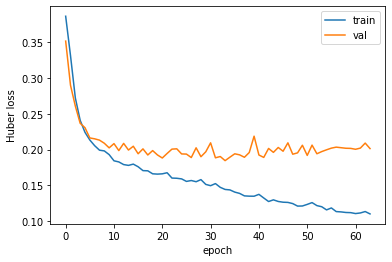

best val: 0.1844499671459198


In [36]:
plt.plot(tr_hist, label="train")
plt.plot(vl_hist, label="val")
plt.xlabel("epoch"); plt.ylabel("Huber loss"); plt.legend(); plt.show()
print("best val:", min(vl_hist))

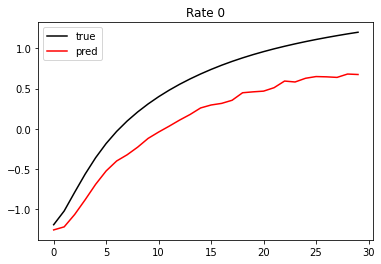

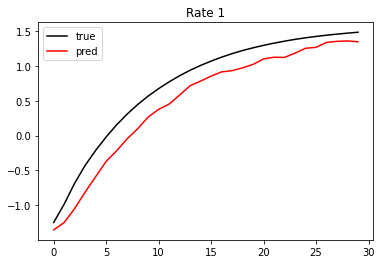

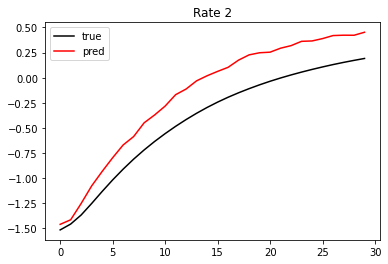

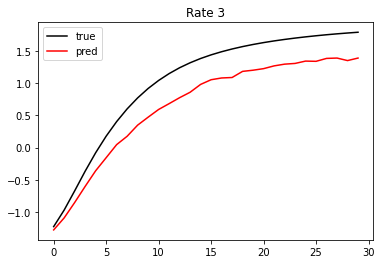

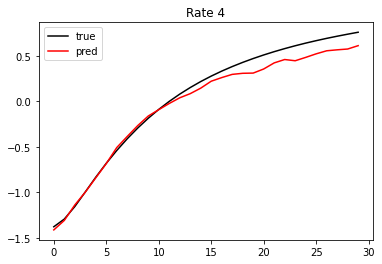

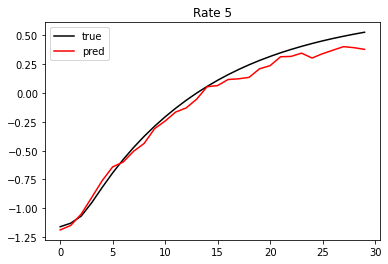

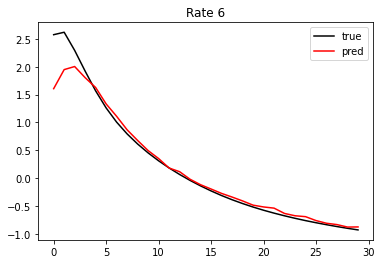

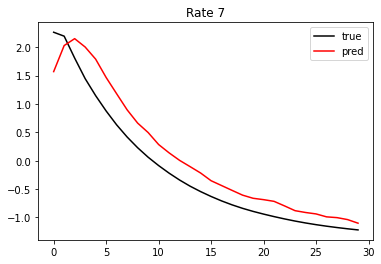

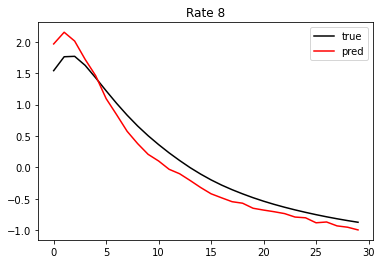

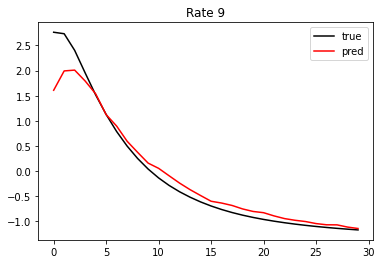

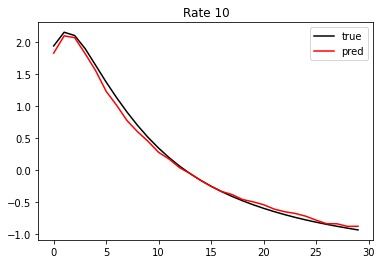

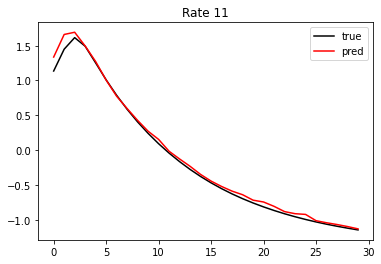

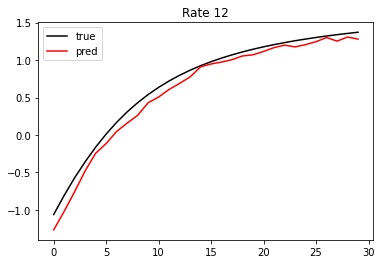

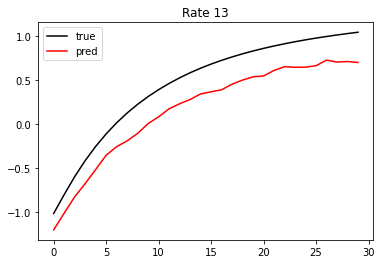

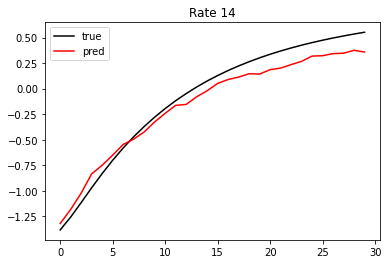

In [42]:
import matplotlib.pyplot as plt

model.eval()
gb, rb = next(iter(train_loader))
gb, rb = gb.to(device), rb.to(device)

with torch.no_grad():
    pred = model(gb)

i = 0  # one sample

true = rb[i].cpu().numpy()
p = pred[i].cpu().numpy()

for k in range(true.shape[-1]):
    plt.figure()
    plt.plot(true[:, k], color="black", label="true")
    plt.plot(p[:, k], color="red", label="pred")
    plt.title(f"Rate {k}")
    plt.legend()
    plt.show()